In [1]:
#Import the libaries

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [2]:
#Load the dataset

df = pd.read_csv("../data/raw/nigeria_retail_sales.csv")

In [3]:
#Check the size of the dataset

df.shape

(1525, 16)

In [4]:
#Look at columns name

df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_age', 'gender',
       'state', 'sales_channel', 'product_category', 'product_name',
       'quantity', 'unit_price_ngn', 'discount_pct', 'payment_method',
       'delivery_days', 'customer_rating', 'returned'],
      dtype='object')

In [5]:
#Show the first 5 rows

df.head()

,order_id,order_date,customer_id,customer_age,gender,state,sales_channel,product_category,product_name,quantity,unit_price_ngn,discount_pct,payment_method,delivery_days,customer_rating,returned
0,ORD100294,2025-11-24,CUST1260,56.0,Male,Delta,Website,Fashion,Sneakers,1,30800.0,0,Pay on Delivery,1.0,4.0,0
1,ORD101002,2025-07-23,CUST1374,27.0,Female,Ogun,WhatsApp,Home & Kitchen,Standing Fan,1,40200.0,0,Card,2.0,5.0,0
2,ORD101285,2025-01-18,CUST1121,32.0,Female,Anambra,Mobile App,ELECTRONICS,Smartphone,2,121300.0,10,Bank Transfer,6.0,3.0,0
3,ORD100043,2025-12-07,CUST1344,45.0,Male,Rivers,Website,Fashion,Handbag,2,22800.0,0,Pay on Delivery,3.0,3.0,0
4,ORD101105,2025-03-08,CUST1540,20.0,Female,Enugu,Website,Electronics,Power Bank,3,11400.0,10,Pay on Delivery,7.0,NaN,0


In [6]:
#Show the last 5 rows

df.tail()

,order_id,order_date,customer_id,customer_age,gender,state,sales_channel,product_category,product_name,quantity,unit_price_ngn,discount_pct,payment_method,delivery_days,customer_rating,returned
1520,ORD100211,2025-09-19,CUST1383,18.0,Male,Lagos,WhatsApp,Groceries,Rice 50kg,1,79200.0,0,Bank Transfer,5.0,NaN,0
1521,ORD100502,2025-12-08,CUST1167,18.0,Male,Anambra,WhatsApp,Electronics,Smartphone,1,125700.0,10,Card,6.0,4.0,0
1522,ORD100537,2025-02-12,CUST1174,36.0,Female,Lagos,WhatsApp,Groceries,Rice 50kg,2,84200.0,0,Card,3.0,4.0,0
1523,ORD101220,2025-08-26,CUST1429,34.0,Male,Oyo,WhatsApp,Electronics,Power Bank,1,12900.0,5,Bank Transfer,1.0,2.0,0
1524,ORD100175,2025-06-18,CUST1577,34.0,Female,Lagos,Mobile App,Electronics,Power Bank,3,12200.0,5,Card,2.0,NaN,0


In [7]:
#Understand the data types

df.dtypes

order_id             object
order_date           object
customer_id          object
customer_age        float64
gender               object
state                object
sales_channel        object
product_category     object
product_name         object
quantity              int64
unit_price_ngn      float64
discount_pct          int64
payment_method       object
delivery_days       float64
customer_rating     float64
returned              int64
dtype: object

In [8]:
#Getting a complete summary of the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1525 entries, 0 to 1524
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1525 non-null   object 
 1   order_date        1525 non-null   object 
 2   customer_id       1525 non-null   object 
 3   customer_age      1450 non-null   float64
 4   gender            1525 non-null   object 
 5   state             1525 non-null   object 
 6   sales_channel     1525 non-null   object 
 7   product_category  1525 non-null   object 
 8   product_name      1525 non-null   object 
 9   quantity          1525 non-null   int64  
 10  unit_price_ngn    1525 non-null   float64
 11  discount_pct      1525 non-null   int64  
 12  payment_method    1485 non-null   object 
 13  delivery_days     1525 non-null   float64
 14  customer_rating   1302 non-null   float64
 15  returned          1525 non-null   int64  
dtypes: float64(4), int64(3), object(9)
memory 

In [9]:
#Statistical Summary

df.describe()

,customer_age,quantity,unit_price_ngn,discount_pct,delivery_days,customer_rating,returned
count,1450.000000,1525.000000,1525.000000,1525.000000,1525.000000,1302.000000,1525.000000
mean,34.342759,2.482623,57681.508197,7.327869,3.732459,3.864823,0.049180
std,37.036146,10.339855,101973.050382,7.531041,2.449067,0.958079,0.216315
min,0.000000,1.000000,8100.000000,0.000000,-1.000000,1.000000,0.000000
25%,27.000000,1.000000,13900.000000,0.000000,2.000000,3.000000,0.000000
50%,33.000000,1.000000,26200.000000,5.000000,4.000000,4.000000,0.000000
75%,39.000000,3.000000,52700.000000,15.000000,5.000000,5.000000,0.000000
max,999.000000,250.000000,485500.000000,20.000000,12.000000,5.000000,1.000000


In [10]:
#Including catergorical variables

df.describe(include="object")

,order_id,order_date,customer_id,gender,state,sales_channel,product_category,product_name,payment_method
count,1525,1525,1525,1525,1525,1525,1525,1525,1485
unique,1500,396,548,2,29,4,10,20,4
top,ORD100926,2025-12-08,CUST1541,Female,Lagos,Website,Electronics,Earbuds,Bank Transfer
freq,2,12,8,841,394,510,431,102,450


In [11]:
#Check for missing values

df.isnull().sum()

order_id              0
order_date            0
customer_id           0
customer_age         75
gender                0
state                 0
sales_channel         0
product_category      0
product_name          0
quantity              0
unit_price_ngn        0
discount_pct          0
payment_method       40
delivery_days         0
customer_rating     223
returned              0
dtype: int64

In [12]:
#Percentage of missing Values

(df.isnull().mean() * 100).sort_values(ascending=False)

customer_rating     14.622951
customer_age         4.918033
payment_method       2.622951
order_id             0.000000
order_date           0.000000
customer_id          0.000000
gender               0.000000
state                0.000000
sales_channel        0.000000
product_category     0.000000
product_name         0.000000
quantity             0.000000
unit_price_ngn       0.000000
discount_pct         0.000000
delivery_days        0.000000
returned             0.000000
dtype: float64

In [13]:
#Check for duplicates

df.duplicated().sum()

25

In [14]:
#List columns name

print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'customer_age', 'gender', 'state', 'sales_channel', 'product_category', 'product_name', 'quantity', 'unit_price_ngn', 'discount_pct', 'payment_method', 'delivery_days', 'customer_rating', 'returned']


In [15]:
#Check for unique values

df["order_id"].unique

<bound method Series.unique of 0       ORD100294
1       ORD101002
2       ORD101285
3       ORD100043
4       ORD101105
          ...    
1520    ORD100211
1521    ORD100502
1522    ORD100537
1523    ORD101220
1524    ORD100175
Name: order_id, Length: 1525, dtype: object>

In [16]:
df.nunique().sort_values()

gender                 2
returned               2
sales_channel          4
payment_method         4
discount_pct           5
customer_rating        5
quantity               7
product_category      10
delivery_days         14
product_name          20
state                 29
customer_age          46
order_date           396
customer_id          548
unit_price_ngn       563
order_id            1500
dtype: int64

In [17]:
#Make a backup

df_raw = df.copy()

In [18]:
df_raw.head()

,order_id,order_date,customer_id,customer_age,gender,state,sales_channel,product_category,product_name,quantity,unit_price_ngn,discount_pct,payment_method,delivery_days,customer_rating,returned
0,ORD100294,2025-11-24,CUST1260,56.0,Male,Delta,Website,Fashion,Sneakers,1,30800.0,0,Pay on Delivery,1.0,4.0,0
1,ORD101002,2025-07-23,CUST1374,27.0,Female,Ogun,WhatsApp,Home & Kitchen,Standing Fan,1,40200.0,0,Card,2.0,5.0,0
2,ORD101285,2025-01-18,CUST1121,32.0,Female,Anambra,Mobile App,ELECTRONICS,Smartphone,2,121300.0,10,Bank Transfer,6.0,3.0,0
3,ORD100043,2025-12-07,CUST1344,45.0,Male,Rivers,Website,Fashion,Handbag,2,22800.0,0,Pay on Delivery,3.0,3.0,0
4,ORD101105,2025-03-08,CUST1540,20.0,Female,Enugu,Website,Electronics,Power Bank,3,11400.0,10,Pay on Delivery,7.0,NaN,0


In [19]:
#Clean the columns name

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ","_")
)

In [20]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_age', 'gender',
       'state', 'sales_channel', 'product_category', 'product_name',
       'quantity', 'unit_price_ngn', 'discount_pct', 'payment_method',
       'delivery_days', 'customer_rating', 'returned'],
      dtype='object')

In [21]:
#Remove duplicate rows

df.duplicated().sum()

25

In [22]:
df = df.drop_duplicates()

In [23]:
df.duplicated().sum()

0

In [24]:
# Convert order_date to a proper datetime value
df["order_date"] = pd.to_datetime(
    df["order_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [25]:
# Keep a clean, independent DataFrame before making further changes
df = df.copy()

# Verify the date conversion
print("Date data type:", df["order_date"].dtype)
print(df["order_date"].head(10))
print("Missing dates:", df["order_date"].isna().sum())

Date data type: datetime64[ns]
0   2025-11-24
1   2025-07-23
2   2025-01-18
3   2025-12-07
4   2025-03-08
5   2025-07-21
6   2025-02-16
7   2025-11-30
8   2025-12-04
9   2025-03-28
Name: order_date, dtype: datetime64[ns]
Missing dates: 40


In [26]:
# Check date conversion results
print(df["order_date"].dtype)
print(df["order_date"].head(10))
print("Missing dates:", df["order_date"].isna().sum())

datetime64[ns]
0   2025-11-24
1   2025-07-23
2   2025-01-18
3   2025-12-07
4   2025-03-08
5   2025-07-21
6   2025-02-16
7   2025-11-30
8   2025-12-04
9   2025-03-28
Name: order_date, dtype: datetime64[ns]
Missing dates: 40


In [27]:
df["order_date"].dtype

dtype('<M8[ns]')

In [28]:
#Check and remove duplicate records

df.duplicated().sum()

0

In [29]:
df[df.duplicated(keep=False)].sort_values("order_id").head(10)

,order_id,order_date,customer_id,customer_age,gender,state,sales_channel,product_category,product_name,quantity,unit_price_ngn,discount_pct,payment_method,delivery_days,customer_rating,returned


In [30]:
#Inspect Categorical columns

df["product_name"].unique()

array(['Sneakers', 'Standing Fan', 'Smartphone', 'Handbag', 'Power Bank',
       'Shea Butter Set', 'Perfume', 'Earbuds', 'Indomie Carton',
       'Bluetooth Speaker', 'Ankara Dress', 'Agbada', 'Garri 10kg',
       'Laptop', 'Rice 50kg', 'Pressure Pot', 'Vegetable Oil 5L',
       'Gas Cooker', 'Hair Extensions', 'Blender'], dtype=object)

In [31]:
# Inspect distinct values in categorical columns
for column in ["product_category", "gender", "payment_method", "sales_channel", "returned"]:
    print(f"\\n{column}:")
    print(df[column].unique())

# Standardise product-category spacing/capitalisation for consistent grouping
df["product_category"] = df["product_category"].astype("string").str.strip().str.title()

\nproduct_category:
['Fashion' 'Home & Kitchen' 'ELECTRONICS' 'Electronics' 'Beauty'
 'Groceries' 'FASHION' 'BEAUTY' 'GROCERIES' 'HOME & KITCHEN']
\ngender:
['Male' 'Female']
\npayment_method:
['Pay on Delivery' 'Card' 'Bank Transfer' 'USSD' nan]
\nsales_channel:
['Website' 'WhatsApp' 'Mobile App' 'Physical Store']
\nreturned:
[0 1]


In [32]:
#Check for missing values

df.isnull().sum()

order_id              0
order_date           40
customer_id           0
customer_age         74
gender                0
state                 0
sales_channel         0
product_category      0
product_name          0
quantity              0
unit_price_ngn        0
discount_pct          0
payment_method       40
delivery_days         0
customer_rating     220
returned              0
dtype: int64

In [33]:
missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

customer_rating    220
customer_age        74
order_date          40
payment_method      40
dtype: int64


In [34]:
#Calculate the missing percentage of missing values

missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percentage", ascending=False)

print(missing_summary.round(2))

                 missing_count  missing_percentage
customer_rating            220               14.67
customer_age                74                4.93
order_date                  40                2.67
payment_method              40                2.67


In [35]:
#Finding the median and using it to fill the missing values

age_median = df["customer_age"].median()
print(age_median)

33.0


In [36]:
df["customer_age"] = df["customer_age"].fillna(age_median)

In [37]:
df["gender"] = df["gender"].fillna("Unknown")

In [38]:
print(df.isnull().sum())

order_id              0
order_date           40
customer_id           0
customer_age          0
gender                0
state                 0
sales_channel         0
product_category      0
product_name          0
quantity              0
unit_price_ngn        0
discount_pct          0
payment_method       40
delivery_days         0
customer_rating     220
returned              0
dtype: int64


In [39]:
# Inspect the median rating, but do not automatically impute missing ratings
rating_median = df["customer_rating"].median()
print("Median of observed customer ratings:", rating_median)
print("Missing customer ratings:", df["customer_rating"].isna().sum())

Median of observed customer ratings: 4.0
Missing customer ratings: 220


In [40]:
# Keep missing customer ratings as missing.
# A blank rating may mean the customer did not submit feedback; filling it with the median
# would distort the rating distribution and downstream analysis.

In [41]:
#Fill missing values with "Unknown" (recommended for now)

df["payment_method"] = df["payment_method"].fillna("Unknown")

In [42]:
#find the most frequent value

print(df["payment_method"].mode())

0    Bank Transfer
Name: payment_method, dtype: object


In [43]:
# Inspect the most common payment method; do not fill missing values with it automatically
print(df["payment_method"].mode())

0    Bank Transfer
Name: payment_method, dtype: object


In [44]:
print(df["payment_method"].isnull().sum())
print(df["payment_method"].value_counts())

0
Bank Transfer      438
Card               404
Pay on Delivery    379
USSD               239
Unknown             40
Name: payment_method, dtype: int64


In [45]:
missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

customer_rating    220
order_date          40
dtype: int64


In [46]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percentage", ascending=False)

print(missing_summary.round(2))

                 missing_count  missing_percentage
customer_rating            220               14.67
order_date                  40                2.67


In [47]:
#Check impossible or suspicious value

df[[
    "customer_age",
    "quantity",
    "unit_price_ngn",
    "discount_pct",
    "delivery_days",
    "customer_rating"
]].describe()

,customer_age,quantity,unit_price_ngn,discount_pct,delivery_days,customer_rating
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1280.000000
mean,34.282667,2.425333,57566.866667,7.316667,3.734667,3.870312
std,36.406442,10.115366,101706.903789,7.544601,2.446546,0.953358
min,0.000000,1.000000,8100.000000,0.000000,-1.000000,1.000000
25%,27.000000,1.000000,14000.000000,0.000000,2.000000,3.000000
50%,33.000000,1.000000,26250.000000,5.000000,4.000000,4.000000
75%,38.000000,3.000000,52600.000000,15.000000,5.000000,5.000000
max,999.000000,250.000000,485500.000000,20.000000,12.000000,5.000000


In [48]:
# Flag suspicious values for investigation; do not remove them automatically
invalid_rows = df[
    (df["customer_age"] < 0) |
    (df["quantity"] <= 0) |
    (df["unit_price_ngn"] < 0) |
    (df["discount_pct"] < 0) |
    (df["discount_pct"] > 100) |
    (df["delivery_days"] < 0) |
    (df["customer_rating"] < 1) |
    (df["customer_rating"] > 5)
]
invalid_rows

,order_id,order_date,customer_id,customer_age,gender,state,sales_channel,product_category,product_name,quantity,unit_price_ngn,discount_pct,payment_method,delivery_days,customer_rating,returned
45,ORD101131,2025-09-02,CUST1241,25.0,Female,Lagos,Mobile App,Groceries,Vegetable Oil 5L,5,13100.0,15,USSD,-1.0,3.0,1
85,ORD100927,2025-04-20,CUST1105,46.0,Male,Delta,Mobile App,Home & Kitchen,Blender,2,28700.0,0,USSD,-1.0,NaN,0
306,ORD101208,2025-04-14,CUST1516,28.0,Female,Lagos,Mobile App,Fashion,Ankara Dress,3,17500.0,0,Bank Transfer,-1.0,NaN,0
562,ORD100602,2025-09-27,CUST1044,18.0,Female,Delta,Website,Groceries,Indomie Carton,4,8700.0,0,Bank Transfer,-1.0,NaN,0
570,ORD100042,2025-09-13,CUST1448,33.0,Female,Kaduna,Mobile App,Home & Kitchen,Pressure Pot,2,34000.0,15,Unknown,-1.0,3.0,0
643,ORD100169,2025-01-09,CUST1155,24.0,Female,rivers,Website,Groceries,Vegetable Oil 5L,5,14400.0,0,Card,-1.0,5.0,0
994,ORD100371,2025-12-28,CUST1171,37.0,Female,Lagos,Mobile App,Electronics,Bluetooth Speaker,1,25500.0,5,Card,-1.0,4.0,0
1101,ORD101286,2025-11-28,CUST1194,18.0,Male,Kano,Physical Store,Beauty,Hair Extensions,1,32100.0,5,Pay on Delivery,-1.0,5.0,0


In [49]:
#Create useful analysis columns (sales before discount) SALES

df["gross_sales_ngn"] = (
    df["quantity"] * df["unit_price_ngn"]
)

In [50]:
# Calculate the discount amount (discount_pct is expressed from 0 to 100)
df["discount_amount_ngn"] = (
    df["gross_sales_ngn"] * df["discount_pct"] / 100
)

In [51]:
# Calculate sales after discount
df["net_sales_ngn"] = (
    df["gross_sales_ngn"] - df["discount_amount_ngn"]
)

In [52]:
#Checking new columns

df[[
    "quantity",
    "unit_price_ngn",
    "discount_pct",
    "gross_sales_ngn",
    "discount_amount_ngn",
    "net_sales_ngn"
]].head()

,quantity,unit_price_ngn,discount_pct,gross_sales_ngn,discount_amount_ngn,net_sales_ngn
0,1,30800.0,0,30800.0,0.0,30800.0
1,1,40200.0,0,40200.0,0.0,40200.0
2,2,121300.0,10,242600.0,24260.0,218340.0
3,2,22800.0,0,45600.0,0.0,45600.0
4,3,11400.0,10,34200.0,3420.0,30780.0


In [53]:
#Converting columns to date

print(df["order_date"].dtype)
print(df["order_date"].head())

datetime64[ns]
0   2025-11-24
1   2025-07-23
2   2025-01-18
3   2025-12-07
4   2025-03-08
Name: order_date, dtype: datetime64[ns]


In [54]:
print(df["order_date"].head(10).to_list())

[Timestamp('2025-11-24 00:00:00'), Timestamp('2025-07-23 00:00:00'), Timestamp('2025-01-18 00:00:00'), Timestamp('2025-12-07 00:00:00'), Timestamp('2025-03-08 00:00:00'), Timestamp('2025-07-21 00:00:00'), Timestamp('2025-02-16 00:00:00'), Timestamp('2025-11-30 00:00:00'), Timestamp('2025-12-04 00:00:00'), Timestamp('2025-03-28 00:00:00')]


In [55]:
print(df["order_date"].dtype)
print("Missing dates:", df["order_date"].isna().sum())
print("Total rows:", len(df))

datetime64[ns]
Missing dates: 40
Total rows: 1500


In [56]:
# Convert ISO-style dates (YYYY-MM-DD); invalid dates become NaT
df["order_date"] = pd.to_datetime(
    df["order_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [57]:
df["order_month"] = df["order_date"].dt.month

df["order_month_name"] = df["order_date"].dt.month_name()

df["order_day"] = df["order_date"].dt.day_name()

In [58]:
df[[
    "order_date",
    "order_month",
    "order_month_name",
    "order_day"
]].head()

,order_date,order_month,order_month_name,order_day
0,2025-11-24,11.0,November,Monday
1,2025-07-23,7.0,July,Wednesday
2,2025-01-18,1.0,January,Saturday
3,2025-12-07,12.0,December,Sunday
4,2025-03-08,3.0,March,Saturday


In [59]:
# Save the cleaned dataset
from pathlib import Path

Path("../data/clean").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/clean/nigeria_retail_sales_clean.csv", index=False)
print("Cleaned dataset saved.")

Cleaned dataset saved.


In [60]:
#Exploratory Data Analysis (EDA)(Finding the total sales and order count)

print("Total net sales:", df["net_sales_ngn"].sum())
print("Number of records:", len(df))
print("Unique orders:", df["order_id"].nunique())
print("Unique customers:", df["customer_id"].nunique())

Total net sales: 158543985.0
Number of records: 1500
Unique orders: 1500
Unique customers: 548


In [61]:
#Product that generated most sales

category_sales = (
    df.groupby("product_category")["net_sales_ngn"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

product_category
Electronics       88130425.0
Groceries         26328385.0
Fashion           22877280.0
Home & Kitchen    15534400.0
Beauty             5673495.0
Name: net_sales_ngn, dtype: float64


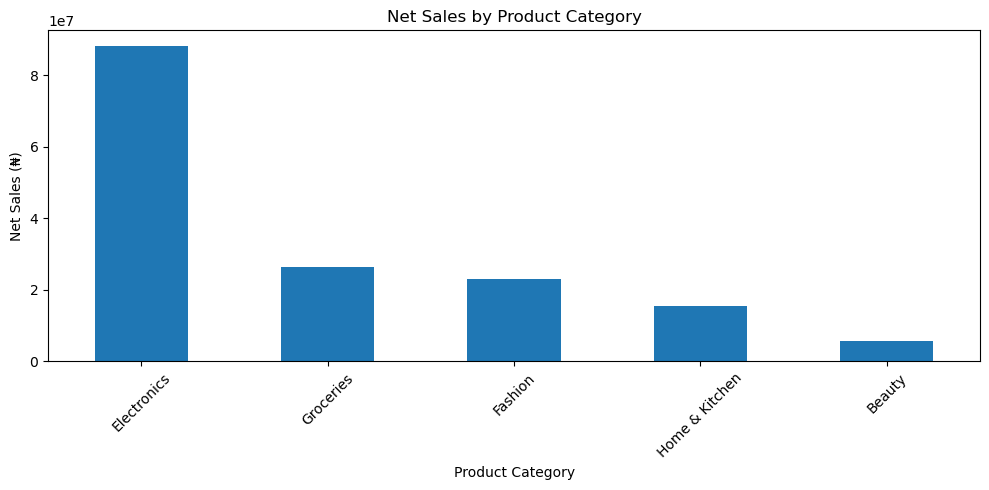

In [62]:
#Visualizing the result

category_sales.plot(kind="bar", figsize=(10, 5))
plt.title("Net Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Net Sales (₦)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
#Best Selling Product

top_product = (
    df.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(top_product)

product_name
Bluetooth Speaker    476
Garri 10kg           458
Vegetable Oil 5L     278
Indomie Carton       248
Sneakers             231
Rice 50kg            229
Agbada               220
Power Bank           150
Earbuds              150
Smartphone           143
Name: quantity, dtype: int64


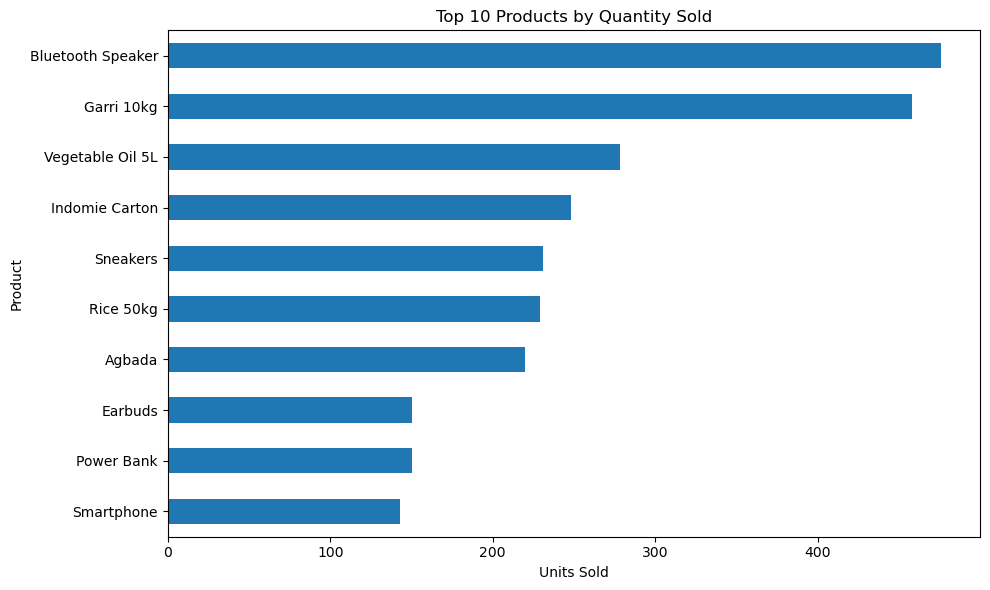

In [64]:
top_product.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [65]:
#State that generates most sales

state_sales = (
     df.groupby("state")["net_sales_ngn"]
    .sum()
    .sort_values(ascending=False)
)
print(state_sales.head(10))

state
Lagos     41664635.0
Delta     14984685.0
Ogun      14266155.0
Kano      12867010.0
Rivers    12791980.0
Oyo       11124270.0
Abuja      8492545.0
FCT        8352395.0
Enugu      8145150.0
Kaduna     7853700.0
Name: net_sales_ngn, dtype: float64


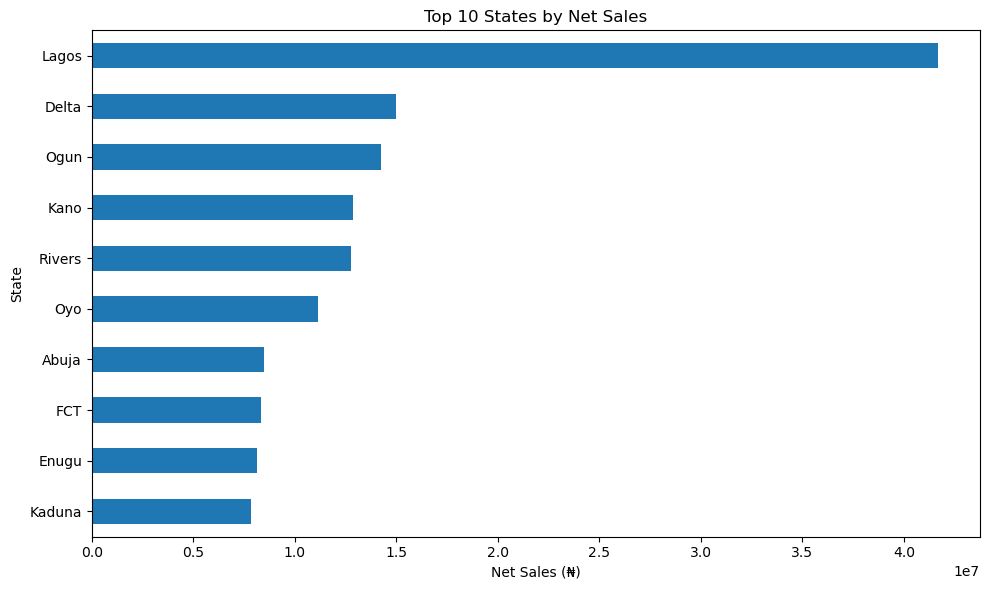

In [66]:
state_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)
plt.title("Top 10 States by Net Sales")
plt.xlabel("Net Sales (₦)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

In [67]:
#Popular Payment Method

payment_counts = df["payment_method"].value_counts()
print(payment_counts)

Bank Transfer      438
Card               404
Pay on Delivery    379
USSD               239
Unknown             40
Name: payment_method, dtype: int64


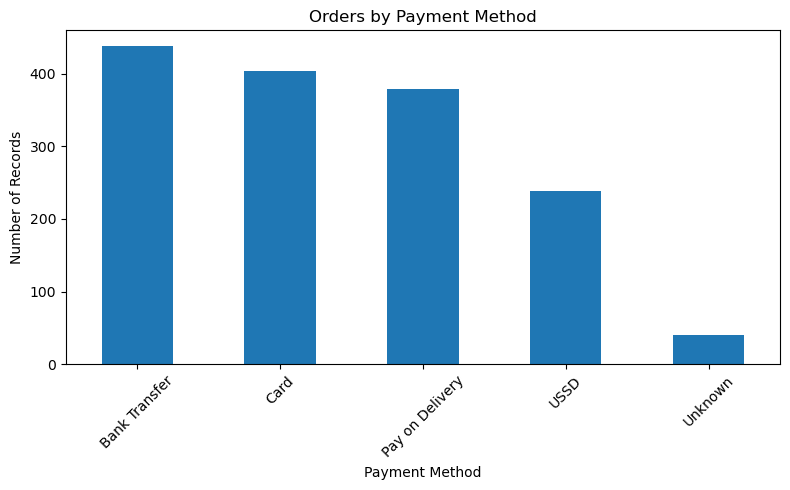

In [68]:
payment_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [69]:
#How sales vary by month

monthly_sales = (
    df.groupby("order_month_name")["net_sales_ngn"]
    .sum()
)

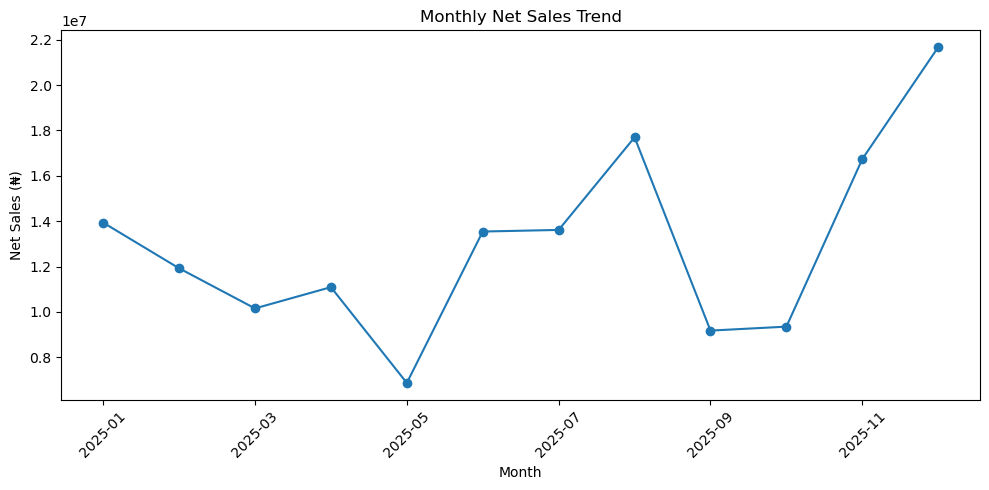

In [70]:
monthly_sales = (
    df.groupby(df["order_date"].dt.to_period("M"))["net_sales_ngn"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales (₦)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [71]:
#Customer Rating

print(df["customer_rating"].describe())
print(df["customer_rating"].value_counts().sort_index())

count    1280.000000
mean        3.870312
std         0.953358
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: customer_rating, dtype: float64
1.0     12
2.0     96
3.0    315
4.0    480
5.0    377
Name: customer_rating, dtype: int64


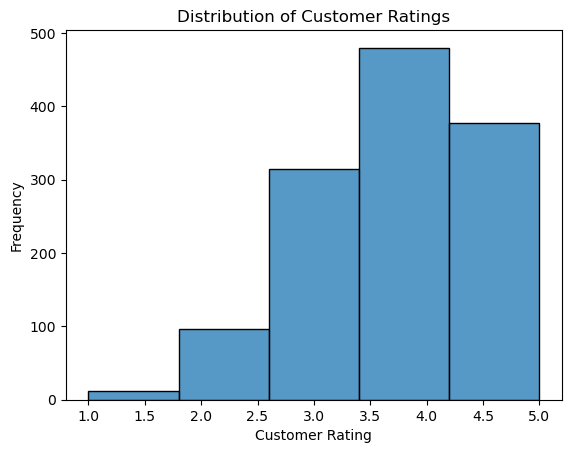

In [72]:
sns.histplot(
    data=df,
    x="customer_rating",
    bins=5
)
plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Frequency")
plt.show()

In [73]:
#Compare sales channels

channel_sales = (
    df.groupby("sales_channel")["net_sales_ngn"]
    .sum()
    .sort_values(ascending=False)
)

print(channel_sales)

sales_channel
Mobile App        52027610.0
Website           50836885.0
WhatsApp          32426965.0
Physical Store    23252525.0
Name: net_sales_ngn, dtype: float64


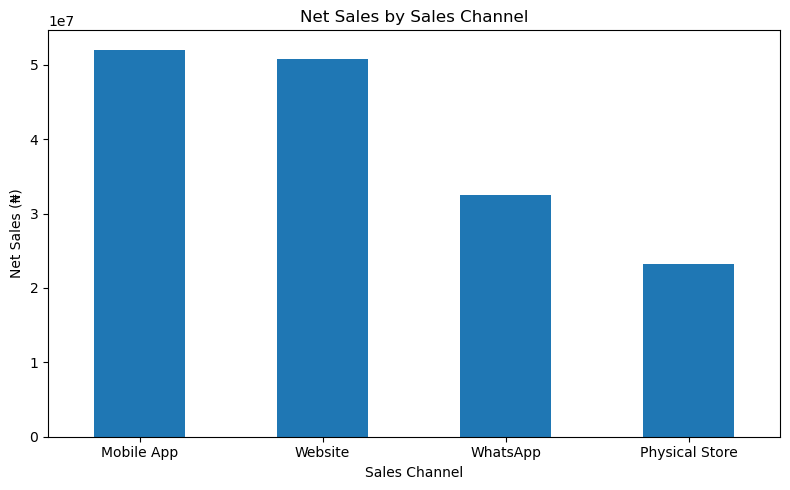

In [74]:
channel_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Net Sales by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Net Sales (₦)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [75]:
#Statistical Analysis (Do customer rating differ between sales channel)

df.groupby("sales_channel")["customer_rating"].agg(
    ["count", "mean", "std"]
)

,count,mean,std
sales_channel,,,
Mobile App,381,3.913386,0.934910
Physical Store,190,4.000000,0.931518
Website,434,3.797235,0.936995
WhatsApp,275,3.836364,1.010233


In [76]:
#Is there association between gender and product category

gender_category = pd.crosstab(
    df["gender"],
    df["product_category"]
)

print(gender_category)

product_category  Beauty          Electronics     Fashion         \
gender                                                             
Female                        89             231             169   
Male                          82             204             152   

product_category  Groceries       Home & Kitchen  
gender                                            
Female                       201             132  
Male                         136             104  


In [77]:
#Using Chi-Square Test of Independece

chi2, p_value, dof, expected = stats.chi2_contingency(
    gender_category
)

print("Chi-square statistics:", chi2)
print("Degree of freedom", dof)
print("P-value", p_value)

Chi-square statistics: 4.943407634240416
Degree of freedom 4
P-value 0.2931536718680623


In [78]:
#Is quanity sold associated with net sales

valid_data = df[
    ["quantity", "net_sales_ngn"]
].dropna()

correlation, p_value = stats.spearmanr(
    valid_data["quantity"],
    valid_data["net_sales_ngn"]
)

print("spearman correlation:", correlation)
print("P-value", p_value)

spearman correlation: 0.45378058986354847
P-value 4.526750588594565e-77


# Stage 5 — Final report, recommendations, and GitHub

In this stage, we turn the analysis into a portfolio-ready summary. Run these cells **after** the cleaning, feature-engineering, and EDA cells above.

Before interpreting the findings, remember:
- `net_sales_ngn` must use `discount_pct / 100` because discounts are percentages.
- Missing customer ratings should generally remain missing rather than being imputed, unless you have a defensible reason to estimate them.
- The dataset contains order records, so record counts and unique order counts are not always interchangeable.
- These are descriptive findings from this dataset; they do not prove causation.


In [79]:
# Stage 5.1 — Create key project metrics
# Recalculate sales values safely in case earlier cells were edited.
df["gross_sales_ngn"] = df["quantity"] * df["unit_price_ngn"]
df["discount_amount_ngn"] = df["gross_sales_ngn"] * df["discount_pct"] / 100
df["net_sales_ngn"] = df["gross_sales_ngn"] - df["discount_amount_ngn"]

total_net_sales = df["net_sales_ngn"].sum()
record_count = len(df)
unique_orders = df["order_id"].nunique()
unique_customers = df["customer_id"].nunique()
average_rating = df["customer_rating"].mean()
return_rate = df["returned"].mean() * 100

category_sales = df.groupby("product_category")["net_sales_ngn"].sum().sort_values(ascending=False)
state_sales = df.groupby("state")["net_sales_ngn"].sum().sort_values(ascending=False)
channel_sales = df.groupby("sales_channel")["net_sales_ngn"].sum().sort_values(ascending=False)
top_products = df.groupby("product_name")["quantity"].sum().sort_values(ascending=False)

print(f"Total net sales: ₦{total_net_sales:,.2f}")
print(f"Rows/records: {record_count:,}")
print(f"Unique orders: {unique_orders:,}")
print(f"Unique customers: {unique_customers:,}")
print(f"Average customer rating (available ratings): {average_rating:.2f}/5")
print(f"Return rate across records: {return_rate:.2f}%")
print(f"Top category by net sales: {category_sales.index[0]} (₦{category_sales.iloc[0]:,.2f})")
print(f"Top state by net sales: {state_sales.index[0]} (₦{state_sales.iloc[0]:,.2f})")
print(f"Top sales channel by net sales: {channel_sales.index[0]} (₦{channel_sales.iloc[0]:,.2f})")
print(f"Top product by units sold: {top_products.index[0]} ({top_products.iloc[0]:,.0f} units)")

Total net sales: ₦158,543,985.00
Rows/records: 1,500
Unique orders: 1,500
Unique customers: 548
Average customer rating (available ratings): 3.87/5
Return rate across records: 4.93%
Top category by net sales: Electronics (₦88,130,425.00)
Top state by net sales: Lagos (₦41,664,635.00)
Top sales channel by net sales: Mobile App (₦52,027,610.00)
Top product by units sold: Bluetooth Speaker (476 units)


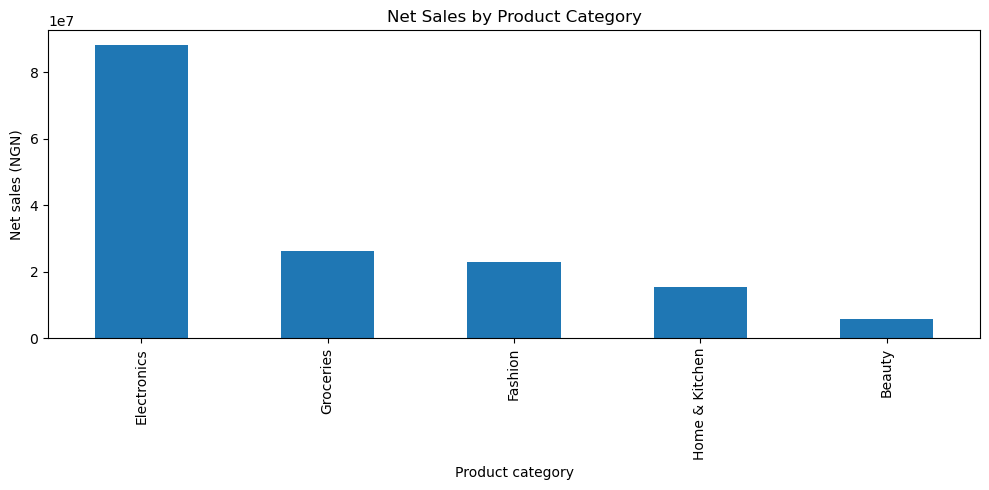

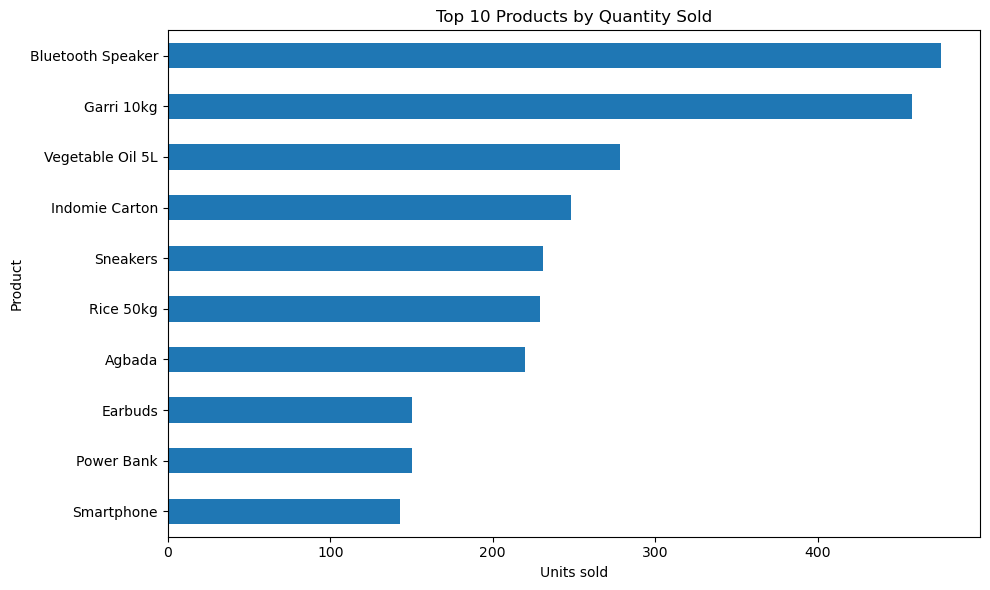

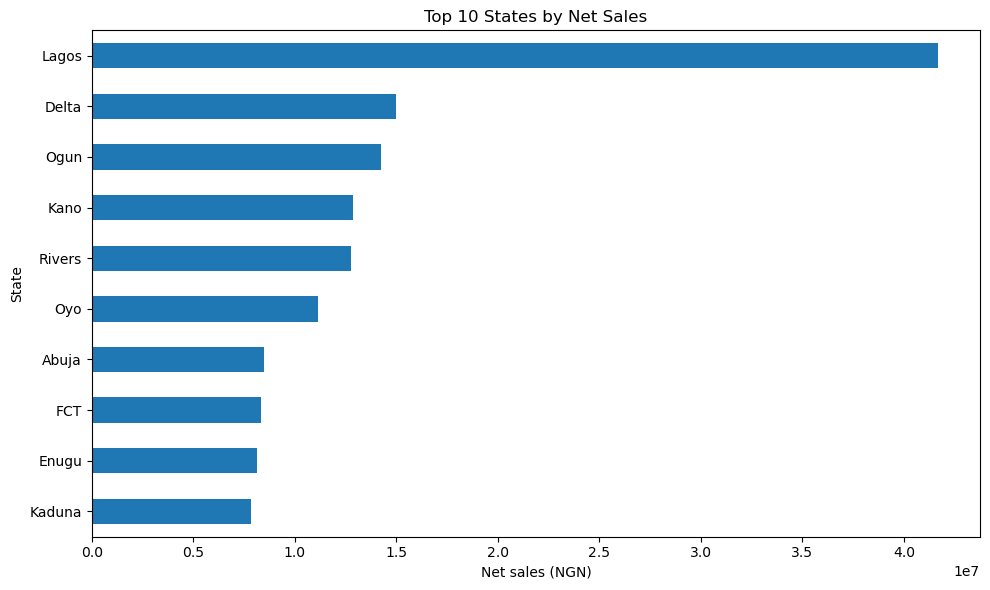

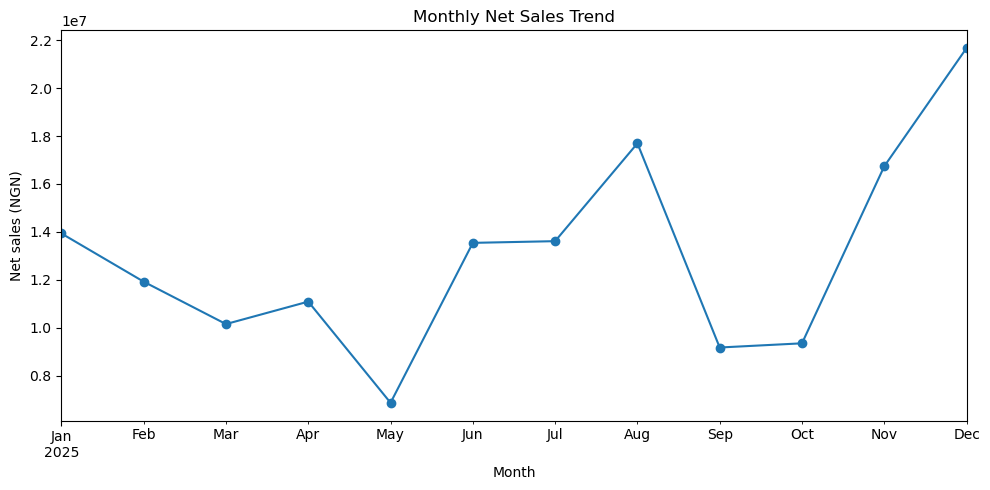

Charts saved in ../images/


In [80]:
# Stage 5.2 — Save portfolio charts to the images folder
from pathlib import Path
Path("../images").mkdir(parents=True, exist_ok=True)

# Net sales by category
ax = category_sales.plot(kind="bar", figsize=(10, 5), title="Net Sales by Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Net sales (NGN)")
plt.tight_layout()
plt.savefig("../images/net_sales_by_category.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Top 10 products by quantity
ax = top_products.head(10).sort_values().plot(kind="barh", figsize=(10, 6), title="Top 10 Products by Quantity Sold")
ax.set_xlabel("Units sold")
ax.set_ylabel("Product")
plt.tight_layout()
plt.savefig("../images/top_10_products.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Top 10 states by net sales
ax = state_sales.head(10).sort_values().plot(kind="barh", figsize=(10, 6), title="Top 10 States by Net Sales")
ax.set_xlabel("Net sales (NGN)")
ax.set_ylabel("State")
plt.tight_layout()
plt.savefig("../images/top_10_states.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Monthly sales trend, ordered chronologically
monthly_sales = df.groupby(df["order_date"].dt.to_period("M"))["net_sales_ngn"].sum()
ax = monthly_sales.plot(kind="line", marker="o", figsize=(10, 5), title="Monthly Net Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Net sales (NGN)")
plt.tight_layout()
plt.savefig("../images/monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Charts saved in ../images/")

In [81]:
# Stage 5.3 — Build a concise findings table
findings = pd.DataFrame({
    "Metric": [
        "Total net sales (NGN)",
        "Number of records",
        "Unique orders",
        "Unique customers",
        "Average customer rating",
        "Return rate (%)",
        "Top product category",
        "Top state",
        "Top sales channel",
        "Top product by units sold"
    ],
    "Result": [
        f"₦{total_net_sales:,.2f}",
        f"{record_count:,}",
        f"{unique_orders:,}",
        f"{unique_customers:,}",
        f"{average_rating:.2f}/5",
        f"{return_rate:.2f}%",
        category_sales.index[0],
        state_sales.index[0],
        channel_sales.index[0],
        top_products.index[0]
    ]
})
findings

,Metric,Result
0,Total net sales (NGN),"₦158,543,985.00"
1,Number of records,"1,500"
2,Unique orders,"1,500"
3,Unique customers,548
4,Average customer rating,3.87/5
5,Return rate (%),4.93%
6,Top product category,Electronics
7,Top state,Lagos
8,Top sales channel,Mobile App
9,Top product by units sold,Bluetooth Speaker


In [82]:
# Stage 5.4 — Save the cleaned data and findings table
from pathlib import Path
Path("../data/clean").mkdir(parents=True, exist_ok=True)

df.to_csv("../data/clean/nigeria_retail_sales_clean.csv", index=False)
findings.to_csv("../data/clean/retail_sales_key_findings.csv", index=False)

print("Saved cleaned dataset and key findings table.")

Saved cleaned dataset and key findings table.


## Stage 5.5 — README and final recommendations

Use the README file supplied with this notebook as the project overview. After running the notebook, update it with the exact results shown by your cells if they differ.

### Recommended business actions to investigate
1. Review the leading product categories and ensure their inventory levels meet demand.
2. Investigate why sales differ by state and channel before allocating more marketing budget.
3. Review low customer ratings and returned orders to identify possible service or product issues.
4. Compare order counts and average order values by channel; total revenue alone can be misleading.
5. Treat the results as descriptive evidence. Use further analysis before making causal claims.

### GitHub checklist
- [ ] Keep the raw CSV unchanged in `data/raw/`.
- [ ] Save the cleaned CSV in `data/clean/`.
- [ ] Save charts in `images/`.
- [ ] Include this notebook and `README.md`.
- [ ] Check that no credentials or private information are committed.
- [ ] Review `git status`, then commit and push your final changes.
